In [1]:
import os
import kagglehub

path = kagglehub.dataset_download("ninadaithal/imagesoasis")
print("Dataset path:", path)

for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 2:
        print(f"{'  ' * depth}{os.path.basename(root)}/  ({len(files)} files)")

Using Colab cache for faster access to the 'imagesoasis' dataset.
Dataset path: /kaggle/input/imagesoasis
imagesoasis/  (0 files)
  Data/  (0 files)
    Non Demented/  (67222 files)
    Very mild Dementia/  (13725 files)
    Moderate Dementia/  (488 files)
    Mild Dementia/  (5002 files)


In [2]:
from pathlib import Path
import re
import pandas as pd

DATA_ROOT = Path(path) / "Data"

df = pd.DataFrame([
    {"path": str(p),
     "class": p.parent.name,
     "label": 0 if "non" in p.parent.name.lower() else 1,
     "subject": re.search(r"OAS\d+_\d+", p.name, re.IGNORECASE).group(0).upper()}
    for p in DATA_ROOT.rglob("*.jpg")
])

print(f"Total slices: {len(df):,}")
print(f"Unique subjects: {df.subject.nunique():,}")
print(df["class"].value_counts())
print(df.label.value_counts(normalize=True).round(3))

Total slices: 86,437
Unique subjects: 347
class
Non Demented          67222
Very mild Dementia    13725
Mild Dementia          5002
Moderate Dementia       488
Name: count, dtype: int64
label
0    0.778
1    0.222
Name: proportion, dtype: float64


In [3]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df.subject))
train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

print(f"Train: {len(train_df):,} slices / {train_df.subject.nunique()} subjects")
print(f"Val:   {len(val_df):,} slices / {val_df.subject.nunique()} subjects")

Train: 67,893 slices / 277 subjects
Val:   18,544 slices / 70 subjects


In [4]:
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from transformers import ViTImageProcessor

processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

tf_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std)
])

tf_val = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std)
])

class OASIS(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row.path).convert("L")
        return {"pixel_values": self.transform(img),
                "labels": torch.tensor(row.label)}

train_ds = OASIS(train_df, tf_train)
val_ds   = OASIS(val_df, tf_val)
print(f"Train dataset: {len(train_ds)}  Val dataset: {len(val_ds)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Train dataset: 67893  Val dataset: 18544


In [16]:
from transformers import ViTForImageClassification, Trainer, TrainingArguments, EarlyStoppingCallback

model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224", num_labels=2, ignore_mismatched_sizes=True,
)

args = TrainingArguments(
    output_dir="/content/vit_oasis_out",
    num_train_epochs=1,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=2,
    remove_unused_columns=False,
    report_to="none",
    logging_steps=50,
)

def accuracy(eval_pred):
    logits, labels = eval_pred
    return {"accuracy": (logits.argmax(-1) == labels).mean()}

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=accuracy,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                        
------------------+----------+----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


In [17]:
trainer.train()
print(trainer.evaluate())

Step,Training Loss,Validation Loss,Accuracy
50,0.405319,0.285510,0.858876
100,0.340518,0.289169,0.852189
150,0.323413,0.264023,0.881201
200,0.284077,0.368655,0.858175
250,0.258525,0.354488,0.854131
300,0.242075,0.351121,0.872789


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'eval_loss': 0.26402294635772705, 'eval_accuracy': 0.8812014667817084, 'eval_runtime': 23.1113, 'eval_samples_per_second': 802.378, 'eval_steps_per_second': 12.548, 'epoch': 0.1413760603204524}


In [18]:
import json
import shutil
from google.colab import files as colab_files

SAVE_DIR = "/content/vit_oasis_best"
trainer.save_model(SAVE_DIR)
processor.save_pretrained(SAVE_DIR)
with open("/content/vit_oasis_best/log_history.json", "w") as f:
    json.dump(trainer.state.log_history, f)
shutil.make_archive("/content/vit_oasis_best", "zip", SAVE_DIR)
colab_files.download("/content/vit_oasis_best.zip")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
model = ViTForImageClassification.from_pretrained("/content/vit_oasis_best")
processor = ViTImageProcessor.from_pretrained("/content/vit_oasis_best")
model.eval()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermed

Loaded 14 log entries
Train points: 6, Eval points: 7


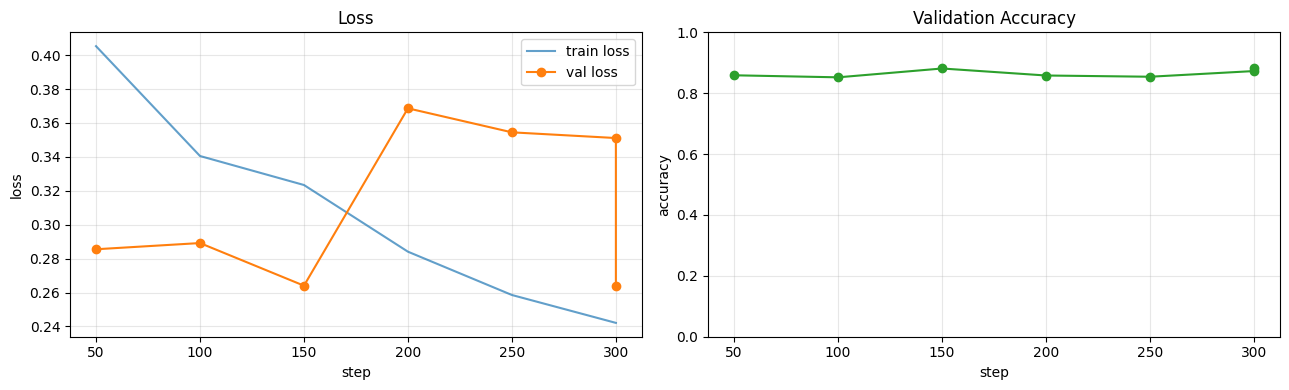

In [20]:
import matplotlib.pyplot as plt
import json
import pandas as pd

with open("/content/vit_oasis_best/log_history.json") as f:
    history = json.load(f)

logs = pd.DataFrame(history)
print(f"Loaded {len(logs)} log entries")

train_logs = logs[logs["loss"].notna() & logs.get("train_loss", pd.Series([float('nan')]*len(logs))).isna()]
if "train_runtime" in logs.columns:
    train_logs = logs[logs["loss"].notna() & logs["train_runtime"].isna()]
else:
    train_logs = logs[logs["loss"].notna()]

eval_logs = logs[logs["eval_loss"].notna()]
print(f"Train points: {len(train_logs)}, Eval points: {len(eval_logs)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(train_logs["step"], train_logs["loss"], label="train loss", alpha=0.7)
axes[0].plot(eval_logs["step"], eval_logs["eval_loss"], "o-", label="val loss", color="C1")
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(eval_logs["step"], eval_logs["eval_accuracy"], "o-", color="C2")
axes[1].set_xlabel("step"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Validation Accuracy"); axes[1].grid(alpha=0.3)
axes[1].set_ylim(0, 1)

plt.tight_layout(); plt.show()

In [21]:
preds_out = trainer.predict(val_ds)
logits = preds_out.predictions             # (N, 2)
y_true = preds_out.label_ids               # (N,)
y_pred = logits.argmax(axis=1)             # (N,)
y_prob = torch.softmax(torch.tensor(logits), dim=-1).numpy()[:, 1]  # P(Demented)

print(f"Total val predictions: {len(y_true)}")
print(f"Predicted Demented: {y_pred.sum()} / {len(y_pred)}")

Total val predictions: 18544
Predicted Demented: 2439 / 18544


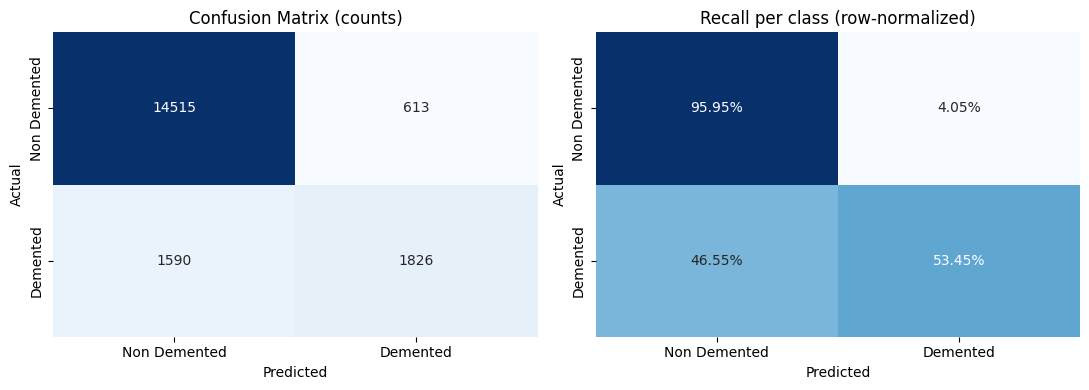

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
labels = ["Non Demented", "Demented"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion Matrix (counts)")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
axes[1].set_title("Recall per class (row-normalized)")

plt.tight_layout();
plt.show()

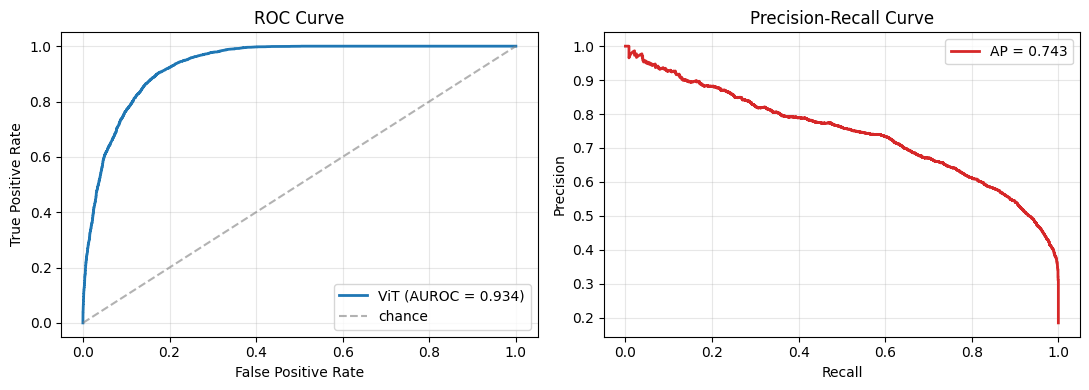


=== Classification Report ===
              precision    recall  f1-score   support

Non Demented     0.9013    0.9595    0.9295     15128
    Demented     0.7487    0.5345    0.6237      3416

    accuracy                         0.8812     18544
   macro avg     0.8250    0.7470    0.7766     18544
weighted avg     0.8732    0.8812    0.8731     18544



In [23]:
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    classification_report,
)

fpr, tpr, _ = roc_curve(y_true, y_prob)
auroc = roc_auc_score(y_true, y_prob)

prec, rec, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(fpr, tpr, label=f"ViT (AUROC = {auroc:.3f})", linewidth=2)
axes[0].plot([0, 1], [0, 1], "--", color="gray", alpha=0.6, label="chance")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec, label=f"AP = {ap:.3f}", linewidth=2, color="C3")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=labels, digits=4))

In [24]:
from sklearn.metrics import accuracy_score

val_with_preds = val_df.reset_index(drop=True).copy()
val_with_preds["pred"] = y_pred
val_with_preds["prob_demented"] = y_prob

patient_level = val_with_preds.groupby("subject").agg(
    true_label=("label", "first"),
    mean_prob=("prob_demented", "mean"),
    n_slices=("path", "count"),
).reset_index()
patient_level["pred"] = (patient_level["mean_prob"] >= 0.5).astype(int)

from sklearn.metrics import accuracy_score
acc_slice   = (y_pred == y_true).mean()
acc_patient = accuracy_score(patient_level["true_label"], patient_level["pred"])
auroc_pat   = roc_auc_score(patient_level["true_label"], patient_level["mean_prob"])

print(f"Slice-level accuracy:   {acc_slice:.4f}  (N={len(y_true)})")
print(f"Patient-level accuracy: {acc_patient:.4f}  (N={len(patient_level)})")
print(f"Patient-level AUROC:    {auroc_pat:.4f}")

Slice-level accuracy:   0.8812  (N=18544)
Patient-level accuracy: 0.9000  (N=70)
Patient-level AUROC:    0.9541


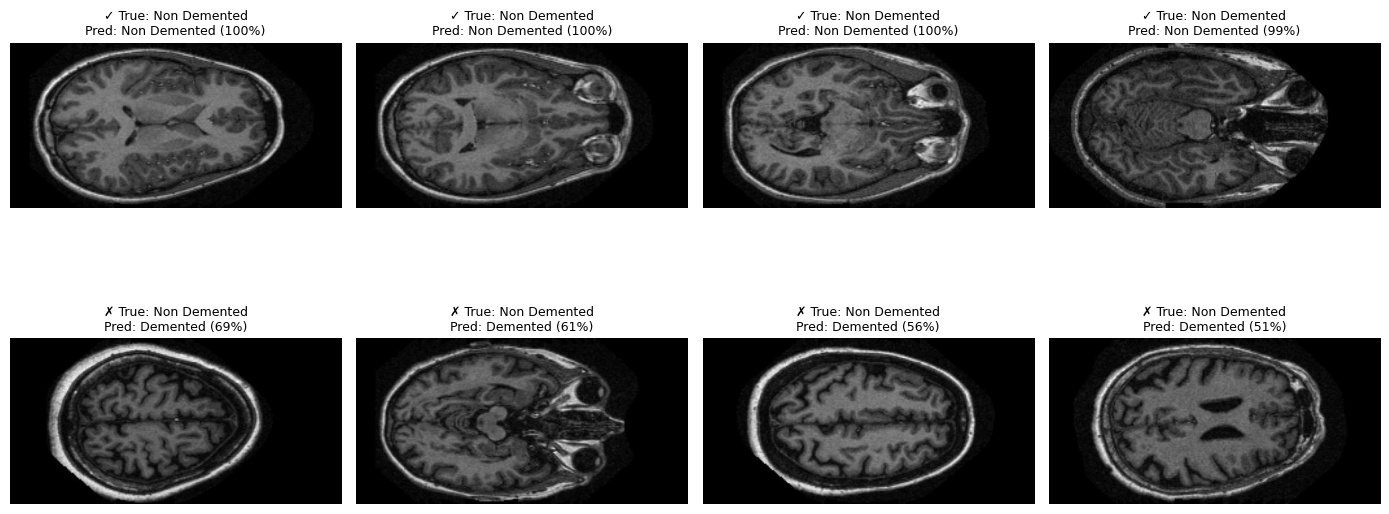

In [25]:
import numpy as np

correct_idx = np.where(y_pred == y_true)[0][:4]
incorrect_idx = np.where(y_pred != y_true)[0][:4]
idx_list = list(correct_idx) + list(incorrect_idx)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
label_names = {0: "Non Demented", 1: "Demented"}

for ax, idx in zip(axes.flat, idx_list):
    img = Image.open(val_df.iloc[idx]["path"]).convert("L")
    true = int(val_df.iloc[idx]["label"])
    pred = int(y_pred[idx])
    prob = y_prob[idx] if pred == 1 else (1 - y_prob[idx])
    mark = "✓" if pred == true else "✗"
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{mark} True: {label_names[true]}\nPred: {label_names[pred]} ({prob:.0%})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()